<a href="https://colab.research.google.com/github/khanrumnaz19-glitch/beach-drowning-detection/blob/main/04_poolwatch_prep.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install -q ultralytics roboflow imagehash
from google.colab import drive, userdata
drive.mount('/content/drive')
from roboflow import Roboflow
import pathlib, yaml, random, collections
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

rf = Roboflow(api_key=userdata.get('ROBOFLOW_KEY'))
project = rf.workspace('rumnazs-capstone-project').project('pool-watch-mpz8r-olp9c')
project.version(1).download('yolov8', location='/content/drive/MyDrive/capstone/data/pw_clean')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 95.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to /content/drive/MyDrive/capstone/data/pw_clean in yolov8:: 100%|██████████| 7252/7252 [01:57<00:00, 61.46it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [4]:
PW = pathlib.Path('/content/drive/MyDrive/capstone/data/pw_clean')
pw_names = yaml.safe_load(open(PW / 'data.yaml'))['names']
print('Classes:', pw_names)
pw_imgs, boxes = [], collections.Counter()
for s in ['train', 'valid', 'test']:
    imgs = list((PW / s / 'images').glob('*'))
    pw_imgs += imgs
    print(s, len(imgs), 'images')
    for f in (PW / s / 'labels').glob('*.txt'):
        for line in f.read_text().splitlines():
            if line.strip(): boxes[pw_names[int(line.split()[0])]] += 1
print('TOTAL', len(pw_imgs), 'images   (dataset page says about 2,851)')
print('Boxes per class:', dict(boxes))

Classes: ['Drowning', 'Swimming']
train 2689 images
valid 624 images
test 311 images
TOTAL 3624 images   (dataset page says about 2,851)
Boxes per class: {'Swimming': 11361, 'Drowning': 2243}


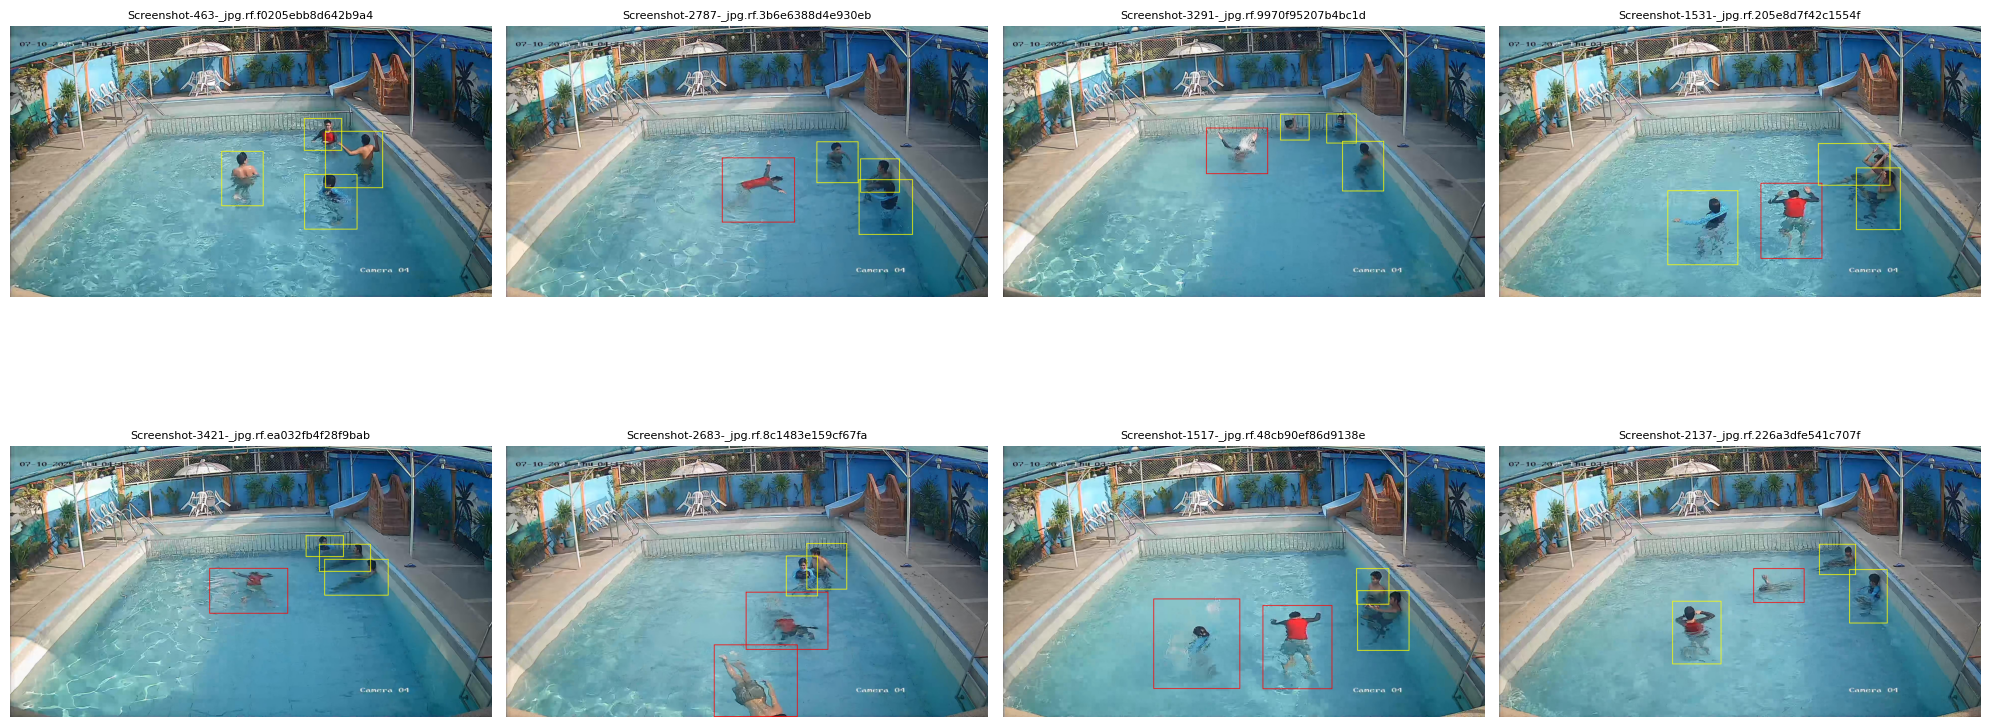

{0: 'Drowning = red', 1: 'Swimming = yellow'}


In [5]:
colors = ['red', 'yellow', 'lime', 'cyan', 'magenta', 'orange']
random.seed(0)
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, p in zip(axes.flat, random.sample(pw_imgs, 8)):
    im = Image.open(p).convert('RGB'); W, H = im.size; d = ImageDraw.Draw(im)
    for line in (p.parent.parent / 'labels' / (p.stem + '.txt')).read_text().splitlines():
        if not line.strip(): continue
        c, x, y, w, h = map(float, line.split()[:5])
        d.rectangle([(x-w/2)*W, (y-h/2)*H, (x+w/2)*W, (y+h/2)*H], outline=colors[int(c) % 6], width=3)
    ax.imshow(im); ax.set_title(p.name[:40], fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()
print({i: f'{n} = {colors[i % 6]}' for i, n in enumerate(pw_names)})

In [6]:
import re
def orig(p): return re.split(r'_(jpg|jpeg|png)\.rf\.', p.name, flags=re.I)[0]
names = collections.Counter(orig(p) for p in pw_imgs)
print(len(names), 'unique original names out of', len(pw_imgs), 'images')
print(sum(1 for v in names.values() if v > 1), 'names appear more than once')
print('repeats by folder:', collections.Counter(p.parent.parent.name for p in pw_imgs if names[orig(p)] > 1))

3624 unique original names out of 3624 images
0 names appear more than once
repeats by folder: Counter()


In [7]:
import imagehash, numpy as np
from tqdm import tqdm
H = np.array([imagehash.phash(Image.open(p).convert('L')).hash.flatten() for p in tqdm(pw_imgs)])
parent = list(range(len(pw_imgs)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
for i in range(len(H)):
    for j in np.nonzero((H[i+1:] != H[i]).sum(1) <= 4)[0]:
        parent[find(i)] = find(i + 1 + j)
groups = collections.defaultdict(list)
for i, p in enumerate(pw_imgs): groups[find(i)].append(p)
keep = [sorted(g)[0] for g in groups.values()]          # one image per group of near-identical frames
print(len(groups), 'distinct frames kept out of', len(pw_imgs))

100%|██████████| 3624/3624 [02:17<00:00, 26.44it/s]


2 distinct frames kept out of 3624


In [8]:
D = '/content/drive/MyDrive/capstone/data/sdd_clean'
ours = []
for s in ['val', 'test']:
    ours += pathlib.Path(f'{D}/split_{s}.txt').read_text().splitlines()
H_ours = np.array([imagehash.phash(Image.open(p).convert('L')).hash.flatten() for p in tqdm(ours)])
idx = {p: i for i, p in enumerate(pw_imgs)}
clash = [p for p in keep if (H_ours != H[idx[p]]).sum(1).min() <= 8]
keep = [p for p in keep if p not in clash]
print(len(clash), 'Pool-Watch frames removed (look like our val/test images)')
print(len(keep), 'Pool-Watch frames ready for training')

100%|██████████| 2215/2215 [09:05<00:00,  4.06it/s]

0 Pool-Watch frames removed (look like our val/test images)
2 Pool-Watch frames ready for training


In [10]:
def num(p):
    m = re.search(r'(\d+)', orig(p)); return int(m.group(1)) if m else -1
def boxes_of(p):
    out = []
    for l in (p.parent.parent / 'labels' / (p.stem + '.txt')).read_text().splitlines():
        if l.strip():
            c, x, y = l.split()[:3]; out.append((int(c), float(x), float(y)))
    return out
def different(a, b, move=0.03):
    if len(a) != len(b) or sorted(c for c, _, _ in a) != sorted(c for c, _, _ in b):
        return True
    for c, x, y in a:
        d = min(((x - x2)**2 + (y - y2)**2) ** 0.5 for c2, x2, y2 in b if c2 == c)
        if d > move:
            return True
    return False

ordered = sorted(pw_imgs, key=num)
keep, last = [], None
for p in ordered:
    b = boxes_of(p)
    if last is None or different(b, last):
        keep.append(p); last = b
print(len(keep), 'distinct frames kept out of', len(pw_imgs))

clash = [p for p in keep if (H_ours != H[idx[p]]).sum(1).min() <= 8]
keep = [p for p in keep if p not in clash]
print(len(clash), 'removed for looking like our val/test;', len(keep), 'ready for training')

1417 distinct frames kept out of 3624
0 removed for looking like our val/test; 1417 ready for training


In [11]:
import shutil
OUT = pathlib.Path('/content/drive/MyDrive/capstone/data/pw_train')
shutil.rmtree(OUT, ignore_errors=True)
(OUT / 'images').mkdir(parents=True, exist_ok=True); (OUT / 'labels').mkdir(exist_ok=True)
remap = {0: 0, 1: 2}            # Pool-Watch Drowning -> Drowning (0), Swimming -> Swimming (2)
NAMES = ['Drowning', 'Person out of water', 'Swimming']
kept_boxes = collections.Counter()
for p in keep:
    shutil.copy(p, OUT / 'images' / p.name)
    lines = []
    for l in (p.parent.parent / 'labels' / (p.stem + '.txt')).read_text().splitlines():
        if l.strip():
            c, *rest = l.split(); c = remap[int(c)]
            lines.append(' '.join([str(c)] + rest[:4])); kept_boxes[NAMES[c]] += 1
    (OUT / 'labels' / (p.stem + '.txt')).write_text('\n'.join(lines))
(OUT / 'pw_train.txt').write_text('\n'.join(str(OUT / 'images' / p.name) for p in keep))
print('Copied', len(keep), 'images; boxes:', dict(kept_boxes))

Copied 1417 images; boxes: {'Swimming': 4382, 'Drowning': 894}
